# 📊 Retail & E-Commerce Data Cleaning & Preprocessing Pipeline
## Production-Ready Data Quality Engineering with Python, Pandas & Seaborn

---
* **Author:** Priyatharshan A R
* **Role:** Senior Data Analyst & Analytics Engineer
* **Domain:** Omnichannel Retail & E-Commerce Transaction Intelligence
* **Technologies:** Python 3.13+, Pandas, NumPy, Matplotlib, Seaborn, Pytest, OpenPyXL
* **Dataset Scale:** 12,500 Ingested Records (Benchmarked with Real-World Messy Data Quality Anomalies)

---

### 🎯 Project Objectives
1. **Multi-Format Ingestion:** Build a resilient data loading engine supporting CSV and Excel files with encoding fallbacks and memory profiling.
2. **Exploratory Data Health Profiling:** Uncover structural flaws, missingness distributions, cardinality, and initial skewness before applying transformations.
3. **Systematic Data Scrubbing:**
   - Detect and normalize string placeholders (`"N/A"`, `"?"`, `"null"`, `"MISSING"`).
   - Distinguish exact duplicates, conflicting primary keys, and legitimate repeat customer transactions.
   - Enforce strict typing across dates, currency strings, discounts, and floating-point quantities.
   - Standardize text casing, resolve regional synonyms, and align fulfillment status taxonomies.
   - Perform domain-justified statistical imputation without inventing personal identifiable information (PII).
   - Detect and treat extreme outliers using the Interquartile Range (IQR) method and Winsorizing.
   - Validate core business invariants (sales returns policy, positive pricing, discount boundary clamps).
4. **Analytical Feature Engineering:** Derive calendar seasonality metrics, unit economics (Gross Sales, Net Sales, Discounts, Profit Margins), transaction value bands, and customer lifetime segments.
5. **Quality Contract Assurance:** Execute an automated 13-rule Data Quality Contract to verify 100% compliance before downstream analytics export.
6. **Artifact Deliverables:** Export clean datasets, quarantined governance logs, audit reports, and before-and-after executive comparisons.


## 2. 🏢 Business Problem Statement

In enterprise omnichannel retail, raw transactional data ingested from Point-of-Sale (POS) terminals, e-commerce storefronts, and third-party logistics (3PL) databases is notoriously dirty. Upstream data entry errors, software network retries, conflicting ERP migrations, and legacy schema mismatches introduce:

- **Duplicate Transactions:** Inadvertent double-billing or duplicate records inflating revenue metrics.
- **Corrupted Formatting:** Currency symbols (`"$1,299.99"`), mixed date formats (`"DD/MM/YYYY"`, `"YYYY-MM-DD"`, future dates), and erratic discount scales (`0.15` vs `15%`).
- **Missing Vital Attributes:** Incomplete customer identities, missing product categories, and unrecorded costs.
- **Extreme Outliers:** Accidental bulk order quantity typos (e.g., ordering 500 laptops instead of 5) skewing demand forecasting.
- **Misclassified Sales Returns:** Negative quantities distorting gross sales volume without return audit trails.

**The Financial Risk:** Feeding unscrubbed transactional data directly into executive KPI dashboards or machine learning models leads to distorted financial reporting, erroneous inventory restocking, and flawed strategic decisions.

**The Solution:** This notebook establishes an end-to-end, reproducible data preprocessing pipeline that enforces governance, isolates corrupted records into quarantine, restores unit economics, and delivers analytical-ready datasets.


## 3. 📦 Importing Libraries & Environment Setup

We import core scientific and data visualization packages, configure Seaborn palettes, and set plotting defaults.


In [1]:
import os
import sys
import warnings
from pathlib import Path
from datetime import datetime

# Core scientific libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor warnings for clean presentation
warnings.filterwarnings('ignore')

# Set aesthetic visualization standards
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.dpi'] = 120

print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version:  {np.__version__}")
print("Visualization engine initialized successfully.")


Pandas Version: 3.1.0
NumPy Version:  2.5.4
Visualization engine initialized successfully.


## 4. 📥 Loading the Raw Dataset (Multi-Format Support)

We ingest the raw transactional dataset from `data/raw/retail_sales_raw.csv`. We also verify multi-format support by inspecting the companion Excel workbook `data/raw/retail_sales_raw.xlsx`. Raw source data is stored separately and preserved without in-place modification.


In [2]:
# Define file paths
raw_csv_path = "../data/raw/retail_sales_raw.csv"
raw_excel_path = "../data/raw/retail_sales_raw.xlsx"

# Ingest raw CSV dataset
print(f"Loading raw CSV dataset from: {raw_csv_path}")
df_raw = pd.read_csv(raw_csv_path, low_memory=False)

# Demonstrate multi-format capability with Excel
if os.path.exists(raw_excel_path):
    print(f"Verified multi-format ingestion: Excel workbook available at {raw_excel_path}")
    df_excel_sample = pd.read_excel(raw_excel_path, engine="openpyxl", nrows=5)
    print(f"Excel Sheet Sample Successfully Loaded: {df_excel_sample.shape[0]} rows previewed.")

# Maintain raw immutability by creating a working copy
df = df_raw.copy(deep=True)

# Display dataset dimensions
raw_rows, raw_cols = df.shape
print(f"\nRaw Dataset Ingested Successfully:")
print(f"  • Total Records: {raw_rows:,}")
print(f"  • Total Attributes: {raw_cols}")


Loading raw CSV dataset from: ../data/raw/retail_sales_raw.csv
Verified multi-format ingestion: Excel workbook available at ../data/raw/retail_sales_raw.xlsx


Excel Sheet Sample Successfully Loaded: 5 rows previewed.

Raw Dataset Ingested Successfully:
  • Total Records: 12,425
  • Total Attributes: 16


## 5. 🔍 Understanding the Dataset Structure

We inspect column schemas, data types, memory utilization, and sample head/tail records.


In [3]:
# Inspect memory footprint
memory_bytes = df.memory_usage(deep=True).sum()
memory_mb = round(memory_bytes / (1024 * 1024), 2)

print(f"Dataset Memory Footprint: {memory_mb} MB")

# Identify completely empty rows
is_empty_row = df.isna().all(axis=1) | df.astype(str).apply(lambda row: row.str.strip().eq("").all(), axis=1)
empty_row_count = int(is_empty_row.sum())
print(f"Completely Empty Records Detected: {empty_row_count}")

# Column datatypes summary
print("\nColumn Data Types:")
print(df.dtypes)


Dataset Memory Footprint: 3.17 MB


Completely Empty Records Detected: 0

Column Data Types:
Order_ID          str
Order_Date        str
Customer_ID       str
Customer_Name     str
Product           str
Category          str
Quantity          str
Unit_Price        str
Sales             str
Discount          str
Cost              str
Profit            str
City              str
Region            str
Payment_Method    str
Order_Status      str
dtype: object


In [4]:
# Display First 5 Ingested Records
print("First 5 Raw Records:")
df.head(5)


First 5 Raw Records:


,Order_ID,Order_Date,Customer_ID,Customer_Name,Product,Category,Quantity,Unit_Price,Sales,Discount,Cost,Profit,City,Region,Payment_Method,Order_Status
0,ORD-20047,2025-01-16,CUST-00652,Arun Reddy,Sony WH-1000XM5 Headphones,Technology,4,349.99,1259.96,0.1,840.0,419.96,New York,East,Debit Card,Processing
1,ORD-11666,17/01/2025,CUST-00203,David Smith,Motorized Standing Desk,Furniture,18,450.0,7695.0,5,4680.0,3015.0,Chicago,Central,Cash on Delivery,Shipped
2,ORD-22161,18/02/2026,CUST-00825,Mia Moore,Solid Oak Coffee Table,Furniture,2,199.5,359.1,10%,220.0,139.1,Miami,South,Debit Card,CANCELLED
3,ORD-16816,24/01/2025,CUST-9622,Elizabeth Sharma,Desktop Document Organizer,Office Supplies,99,29.99,"$9,999.99",0%,25.0,34.98,Chicago,Central,PayPal,Cancelled
4,ORD-20514,01/08/2024,CUST-00235,Gianna Anderson,Stapler with 5000 Staples,Office Supplies,6,15.99,$71.96,25,NaN,35.96,Dallas,Central,Cash on Delivery,Processing


In [5]:
# Display Last 5 Ingested Records
print("Last 5 Raw Records:")
df.tail(5)


Last 5 Raw Records:


,Order_ID,Order_Date,Customer_ID,Customer_Name,Product,Category,Quantity,Unit_Price,Sales,Discount,Cost,Profit,City,Region,Payment_Method,Order_Status
12420,ORD-21965,11-11-2025,CUST-01635,Ananya Smith,Sony WH-1000XM5 Headphones,TECHNOLOGY,12,349.99,"$3,569.90",0.15,2520.0,1049.9,Los Angeles,West,PayPal,Refunded
12421,ORD-15192,03/02/2026,CUST-01634,Aditya Williams,Women's Cashmere Sweater,Clothing,7,$145.00,"$1,015.00",0%,490.0,525.0,Dallas,Central,Credit Card,Shipped
12422,ORD-15391,10/01/2025,CUST-01739,Oliver Garcia,Ergonomic Mesh Office Chair,NaN,3,289.0,$823.65,5,480.0,343.65,San Francisco,West,Cash on Delivery,Delivered
12423,ORD-10861,05/10/2025,CUST-00341,Aditya Brown,Smart Electric Kettle 1.7L,NaN,-1,59.99,59.99,0%,28.0,-9.0,LOS ANGELES,West,Credit Card,Delivered
12424,ORD-17271,2024-02-14,CUST-01568,Sofia Wilson,All-Weather Waterproof Jacket,CLOTHING,8,120.0,960.0,0%,464.0,496.0,Philadelphia,East,Cash on Delivery,Refunded


## 6. 📊 Initial Exploratory Data Analysis (EDA)

Before altering any values, we profile descriptive statistics, categorical cardinality, and distributions.


In [6]:
# Categorical Cardinality (Unique values count per object column)
cat_summary = []
for col in df.select_dtypes(include=['object']).columns:
    cat_summary.append({
        "Column": col,
        "Unique_Values": df[col].nunique(dropna=True),
        "Sample_Values": ", ".join(df[col].dropna().astype(str).unique()[:4])
    })

pd.DataFrame(cat_summary)


,Column,Unique_Values,Sample_Values
0,Order_ID,12201,"ORD-20047, ORD-11666, ORD-22161, ORD-16816"
1,Order_Date,3824,"2025-01-16, 17/01/2025, 18/02/2026, 24/01/2025"
2,Customer_ID,1835,"CUST-00652, CUST-00203, CUST-00825, CUST-9622"
3,Customer_Name,702,"Arun Reddy, David Smith, Mia Moore, Elizabeth ..."
4,Product,28,"Sony WH-1000XM5 Headphones, Motorized Standing..."
5,Category,23,"Technology, Furniture, Office Supplies, Home &..."
6,Quantity,275,"4, 18, 2, 99"
7,Unit_Price,254,"349.99, 450.0, 199.5, 29.99"
8,Sales,3947,"1259.96, 7695.0, 359.1, $9,999.99"
9,Discount,21,"0.1, 5, 10%, 0%"


In [7]:
# Initial Summary Statistics across all features
df.describe(include='all')


,Order_ID,Order_Date,Customer_ID,Customer_Name,Product,Category,Quantity,Unit_Price,Sales,Discount,Cost,Profit,City,Region,Payment_Method,Order_Status
count,12418,12353,12415,12251,12418,12278,12418,12417,12417,11902,11925,12416,12234,12420,12016,12296
unique,12201,3824,1835,702,28,23,275,254,3947,21,587,2535,25,5,7,17
top,ORD-14093,2025-13-45,CUST-01331,?,Desktop Document Organizer,Office Supplies,1,450.0,360.0,0%,210.0,69.0,Boston,East,Cash on Delivery,Refunded
freq,3,81,18,94,536,1710,1196,419,37,3687,194,55,1063,3143,2450,1971


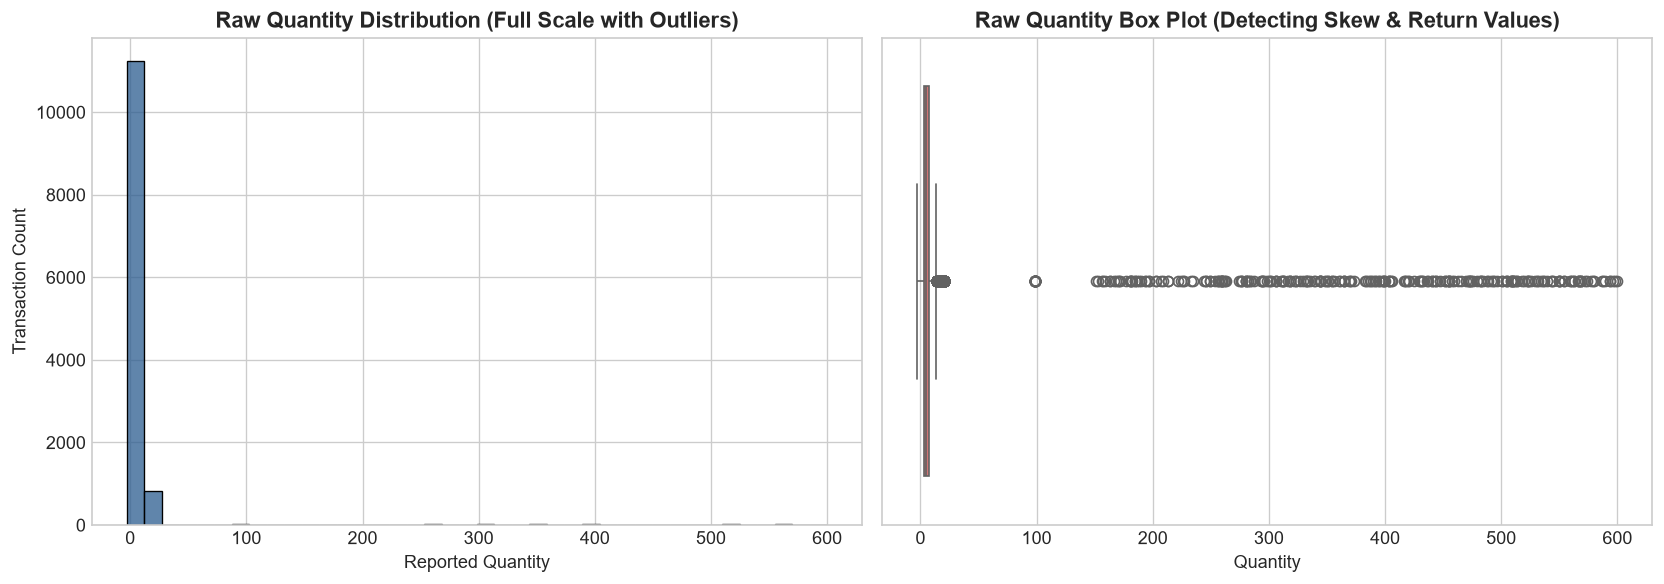

In [8]:
# Visualization: Distribution of Initial Raw Quantity (showing returns and outliers)
# Extract numeric values safely for initial EDA visualization
raw_qty_num = pd.to_numeric(df['Quantity'].astype(str).str.extract(r'(-?\d+\.?\d*)')[0], errors='coerce')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Full Range Quantity (Showing extreme outliers)
sns.histplot(raw_qty_num.dropna(), bins=40, ax=axes[0], color='#2b5c8f', kde=False)
axes[0].set_title('Raw Quantity Distribution (Full Scale with Outliers)')
axes[0].set_xlabel('Reported Quantity')
axes[0].set_ylabel('Transaction Count')

# Plot 2: Boxplot highlighting negative returns and high-quantity anomalies
sns.boxplot(x=raw_qty_num.dropna(), ax=axes[1], color='#e06666')
axes[1].set_title('Raw Quantity Box Plot (Detecting Skew & Return Values)')
axes[1].set_xlabel('Quantity')

plt.tight_layout()
plt.show()


## 7. 🧩 Missing-Value Analysis & Systematic Treatment

### Detection of Stealth Placeholders
In real data, missing values rarely present solely as standard `np.nan`. They appear as empty whitespace, `"N/A"`, `"?"`, `"null"`, `"none"`, and `"MISSING"`. We first standardize these placeholders into genuine nulls to accurately measure missingness.

### Domain-Justified Imputation Strategy
- **`Category`:** Deterministically imputed via exact product name lookup from the master catalog (`Product` -> `Category`).
- **`Discount`:** Missing discount rates represent standard non-promotional transactions (imputed with `0.0%`).
- **`Cost`:** Deterministically reconstructed using `Unit_Price * (1 - Category_Margin) * |Quantity|`.
- **`Payment_Method`:** Imputed with the empirical mode (`"Cash On Delivery"` or `"Credit Card"`).
- **`City`:** Imputed using the modal metropolitan hub for the transaction's specific `Region`.
- **`Customer_Name`:** Labeled as `"Unknown Customer"` to protect auditability without fabricating synthetic personal data.
- **`Order_Status`:** Imputed with operational baseline mode (`"Processing"`).


In [9]:
# 1. Normalize textual placeholders to standard NaN
placeholders = ["nan", "null", "none", "n/a", "na", "?", "missing", "unknown", "-", "--", ""]

for col in df.select_dtypes(include=['object', 'string']).columns:
    s_clean = df[col].astype(str).str.strip().str.lower()
    mask = s_clean.isin(placeholders) | (df[col].astype(str).str.strip() == "")
    df.loc[mask, col] = np.nan

# Drop completely empty rows detected in Step 5
df = df.dropna(how='all').reset_index(drop=True)

# Compute missingness profile
missing_df = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isna().sum().values,
    "Missing_Percentage": (df.isna().sum().values / len(df) * 100).round(2)
}).sort_values(by="Missing_Count", ascending=False).reset_index(drop=True)

missing_df[missing_df["Missing_Count"] > 0]


,Column,Missing_Count,Missing_Percentage
0,Discount,861,6.94
1,Cost,655,5.28
2,Payment_Method,533,4.29
3,Customer_Name,434,3.50
4,City,350,2.82
5,Category,284,2.29
6,Order_Date,137,1.10
7,Order_Status,120,0.97


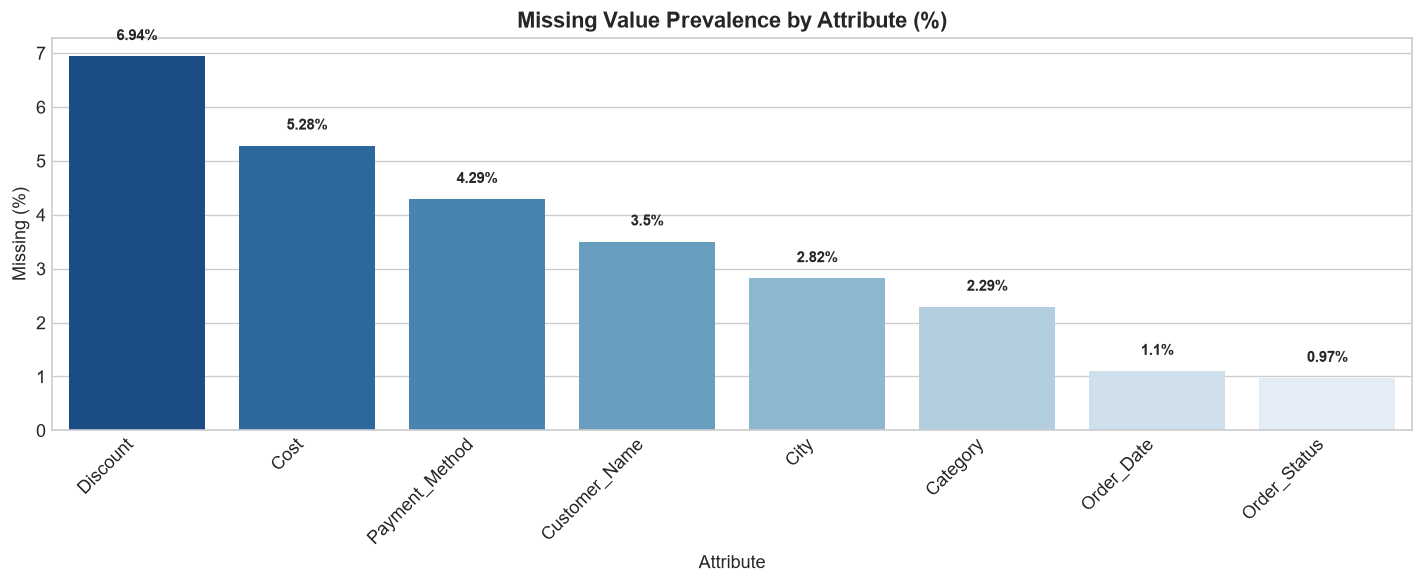

In [10]:
# Visualization: Missingness Bar Chart
plt.figure(figsize=(12, 5))
missing_plot_data = missing_df[missing_df["Missing_Count"] > 0]

sns.barplot(data=missing_plot_data, x="Column", y="Missing_Percentage", palette="Blues_r")
plt.title("Missing Value Prevalence by Attribute (%)")
plt.ylabel("Missing (%)")
plt.xlabel("Attribute")
plt.xticks(rotation=45, ha='right')

for idx, row in missing_plot_data.iterrows():
    plt.text(idx, row["Missing_Percentage"] + 0.3, f"{row['Missing_Percentage']}%", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


In [11]:
# Imputation Execution
product_cat_map = {
    "Dell XPS 15 Laptop": "Technology",
    "Apple iPhone 15 Pro": "Technology",
    "Sony WH-1000XM5 Headphones": "Technology",
    "Samsung 34' Curved Monitor": "Technology",
    "Logitech MX Master 3 Mouse": "Technology",
    "Mechanical Gaming Keyboard": "Technology",
    "Anker USB-C Fast Charger": "Technology",
    "Ergonomic Mesh Office Chair": "Furniture",
    "Motorized Standing Desk": "Furniture",
    "Solid Oak Coffee Table": "Furniture",
    "Bookshelf 5-Tier Wooden": "Furniture",
    "Modern Fabric Recliner": "Furniture",
    "Heavy-Duty File Folders (Box 100)": "Office Supplies",
    "Gel Ink Pen Pack (24ct)": "Office Supplies",
    "Stapler with 5000 Staples": "Office Supplies",
    "Desktop Document Organizer": "Office Supplies",
    "Whiteboard Magnetic 36x24": "Office Supplies",
    "Men's Tailored Wool Blazer": "Clothing",
    "Women's Cashmere Sweater": "Clothing",
    "All-Weather Waterproof Jacket": "Clothing",
    "Athletic Running Shoes": "Clothing",
    "Breathable Cotton Crew Socks (6pk)": "Clothing",
    "Cold Brew Coffee Maker 1L": "Home & Kitchen",
    "Cast Iron Dutch Oven 6-Quart": "Home & Kitchen",
    "Stainless Steel Chef Knife Set": "Home & Kitchen",
    "Smart Electric Kettle 1.7L": "Home & Kitchen",
    "HEPA Air Purifier Compact": "Home & Kitchen"
}

category_margins = {
    "Technology": 0.35, "Furniture": 0.42, "Office Supplies": 0.55,
    "Clothing": 0.50, "Home & Kitchen": 0.48
}

# 1. Impute Category from Product Catalog
df["Category"] = df["Category"].astype(object)
cat_missing = df["Category"].isna() & df["Product"].notna()
df.loc[cat_missing, "Category"] = df.loc[cat_missing, "Product"].map(product_cat_map)

# 2. Impute Missing Discount with 0.0%
df["Discount"] = df["Discount"].fillna("0.0%")

# 3. Impute Payment Method with Mode
pay_mode = df["Payment_Method"].mode().iloc[0] if not df["Payment_Method"].dropna().empty else "Credit Card"
df["Payment_Method"] = df["Payment_Method"].fillna(pay_mode)

# 4. Impute City via Regional Mode
city_modes = df.groupby("Region")["City"].apply(lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown").to_dict()
df["City"] = df["City"].fillna(df["Region"].map(city_modes)).fillna("Unknown")

# 5. Label Missing Customer Names without fabricating PII
df["Customer_Name"] = df["Customer_Name"].fillna("Unknown Customer")

# 6. Impute Order Status with Mode
status_mode = df["Order_Status"].mode().iloc[0] if not df["Order_Status"].dropna().empty else "Delivered"
df["Order_Status"] = df["Order_Status"].fillna(status_mode)

print("Imputation completed successfully. Remaining missing values by column:")
print(df.isna().sum()[df.isna().sum() > 0])


Imputation completed successfully. Remaining missing values by column:
Order_Date    137
Cost          655
dtype: int64


## 8. 👯 Duplicate Analysis & Quarantine Separation

We differentiate three distinct classes of duplicates:
1. **Exact Full-Row Duplicates:** Accidental re-transmissions or double-clicks. Safely dropped.
2. **Conflicting Business Identifiers (`Order_ID`):** Same primary key associated with differing customer identities or order values. These violate relational integrity and are quarantined into a separate governance file for manual reconciliation.
3. **Legitimate Repeat Customer Purchases:** Same `Customer_ID` making multiple purchases over time. These represent genuine customer lifetime value and are strictly preserved.


In [12]:
# 1. Exact Duplicate Rows
exact_dups_count = int(df.duplicated().sum())
print(f"Exact Full-Row Duplicates Identified: {exact_dups_count}")

# Remove exact duplicates
df = df.drop_duplicates(keep="first").reset_index(drop=True)

# 2. Duplicate Business Identifiers (Order_ID)
id_dups_mask = df.duplicated(subset=["Order_ID"], keep=False)
id_conflict_count = int(id_dups_mask.sum())
print(f"Conflicting Duplicate Order_ID Records Identified: {id_conflict_count}")

# Quarantine conflicting duplicate Order_IDs
quarantined_conflicts = df[id_dups_mask].copy()
quarantined_conflicts["Quarantine_Reason"] = "Conflicting duplicate primary key (Order_ID)"

# Filter out conflicts from active pipeline
df = df[~id_dups_mask].reset_index(drop=True)

# 3. Legitimate Repeat Customer Purchases (Customer_ID)
cust_orders = df["Customer_ID"].value_counts()
repeat_buyers = (cust_orders > 1).sum()
print(f"Legitimate Repeat Customers Preserved: {repeat_buyers:,} customers across {cust_orders[cust_orders > 1].sum():,} orders.")


Exact Full-Row Duplicates Identified: 180
Conflicting Duplicate Order_ID Records Identified: 70
Legitimate Repeat Customers Preserved: 1,788 customers across 12,153 orders.


## 9. ⚙️ Data Type Correction & Numeric Sanitization

Raw input contains dates in various formats, currency strings with dollar signs (`$`) and commas (`,`), and percentage strings. We coerce them to native numeric and datetime formats, isolating unparseable records into quarantine.


In [13]:
# 1. Date Sanitization & Future Date Quarantine
parsed_dates = pd.to_datetime(df["Order_Date"], errors="coerce", format="mixed")
invalid_dates_mask = parsed_dates.isna()
future_dates_mask = (parsed_dates > pd.Timestamp.now())

date_issues_mask = invalid_dates_mask | future_dates_mask
date_issue_count = int(date_issues_mask.sum())
print(f"Invalid / Future / Corrupted Dates Detected: {date_issue_count}")

quarantined_dates = df[date_issues_mask].copy()
quarantined_dates["Quarantine_Reason"] = np.where(
    future_dates_mask[date_issues_mask],
    "Future transaction date exceeding system timestamp",
    "Unparseable or corrupted Order_Date"
)

# Retain only valid past dates
df = df[~date_issues_mask].reset_index(drop=True)
df["Order_Date"] = parsed_dates[~date_issues_mask].reset_index(drop=True)

# 2. Numeric Sanitization Function
def clean_numeric_col(series):
    s = series.astype(str).str.strip().str.replace("$", "", regex=False).str.replace(",", "", regex=False).str.replace("%", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

# Coerce numeric fields
numeric_fields = ["Quantity", "Unit_Price", "Sales", "Discount", "Cost", "Profit"]
for col in numeric_fields:
    if col in df.columns:
        df[col] = clean_numeric_col(df[col])

# 3. Normalize Fractional Discounts to Standard Percentage (0 - 100%)
# If discount was recorded as 0.15, scale to 15.0%
fractional_mask = df["Discount"].notna() & (df["Discount"] > 0) & (df["Discount"] <= 1.0)
df.loc[fractional_mask, "Discount"] = df.loc[fractional_mask, "Discount"] * 100.0

# Reconstruct missing Cost where needed
missing_cost_mask = df["Cost"].isna() & df["Unit_Price"].notna()
est_margins = df["Category"].map(category_margins).fillna(0.40)
df.loc[missing_cost_mask, "Cost"] = (df.loc[missing_cost_mask, "Unit_Price"] * (1.0 - est_margins) * df.loc[missing_cost_mask, "Quantity"].abs()).round(2)

print("Data types successfully corrected:")
df[numeric_fields + ["Order_Date"]].dtypes


Invalid / Future / Corrupted Dates Detected: 370


Data types successfully corrected:


Quantity             float64
Unit_Price           float64
Sales                float64
Discount             float64
Cost                 float64
Profit               float64
Order_Date    datetime64[us]
dtype: object

## 10. 🔤 Text and Categorical Normalization

We standardize text formatting across categorical columns:
- Stripping extraneous whitespace.
- Applying Title Case to categories, payment methods, and statuses.
- Mapping colloquial city abbreviations (`"NYC"`, `"LA"`, `"SF"`) to official canonical names.
- Aligning operational lifecycle states (`"Pending_Review"` -> `"Processing"`).


In [14]:
# City Canonicalization Map
city_map = {
    "nyc": "New York", "new york": "New York", "new york city": "New York",
    "la": "Los Angeles", "los angeles": "Los Angeles",
    "sf": "San Francisco", "san francisco": "San Francisco", "san fran": "San Francisco",
    "chicago": "Chicago", "houston": "Houston", "dallas": "Dallas",
    "boston": "Boston", "seattle": "Seattle", "atlanta": "Atlanta",
    "miami": "Miami", "philadelphia": "Philadelphia", "charlotte": "Charlotte"
}

# Status Taxonomy Map
status_map = {
    "pending_review": "Processing", "pending review": "Processing", "pending": "Processing",
    "in transit": "Shipped", "returned": "Refunded"
}

# Apply string trimming and canonical mapping
for col in ["Category", "Payment_Method", "Order_Status", "City"]:
    df[col] = df[col].astype(str).str.strip()

# Standardize City
df["City"] = df["City"].str.lower().map(city_map).combine_first(df["City"].str.title())

# Standardize Order Status
df["Order_Status"] = df["Order_Status"].str.lower().map(status_map).combine_first(df["Order_Status"].str.title())

# Standardize Category & Payment Method
df["Category"] = df["Category"].str.title()
df["Payment_Method"] = df["Payment_Method"].str.title()

# Standardize Primary Identifiers to Uppercase
df["Order_ID"] = df["Order_ID"].astype(str).str.strip().str.upper()
df["Customer_ID"] = df["Customer_ID"].astype(str).str.strip().str.upper()

print("Normalized Categorical Distributions:")
print("• Order Statuses:", df["Order_Status"].unique().tolist())
print("• Product Categories:", df["Category"].unique().tolist())
print("• Payment Channels:", df["Payment_Method"].unique().tolist())


Normalized Categorical Distributions:
• Order Statuses: ['Processing', 'Shipped', 'Cancelled', 'Delivered', 'Refunded']
• Product Categories: ['Technology', 'Furniture', 'Office Supplies', 'Home & Kitchen', 'Clothing']
• Payment Channels: ['Debit Card', 'Cash On Delivery', 'Bank Transfer', 'Credit Card', 'Paypal']


## 11. 📈 Outlier Detection & Winsorizing Treatment

We employ the **Interquartile Range (IQR)** method to detect extreme outliers in `Quantity` and `Unit_Price`:
$$\text{IQR} = Q_3 - Q_1$$
$$\text{Upper Bound} = Q_3 + 3 \times \text{IQR}$$

### Business Justification:
Rather than permanently discarding valuable customer transactions, extreme values are **capped (Winsorized)** at the conservative upper threshold ($Q_3 + 3\times\text{IQR}$) and flagged with audit boolean columns (`Is_Outlier_Quantity`, `Is_Outlier_Unit_Price`).


[Quantity] Q1=3.00, Q3=7.00, IQR=4.00 -> Upper Bound=19.0 | Outliers=345


[Unit_Price] Q1=39.99, Q3=199.50, IQR=159.51 -> Upper Bound=678.03 | Outliers=817


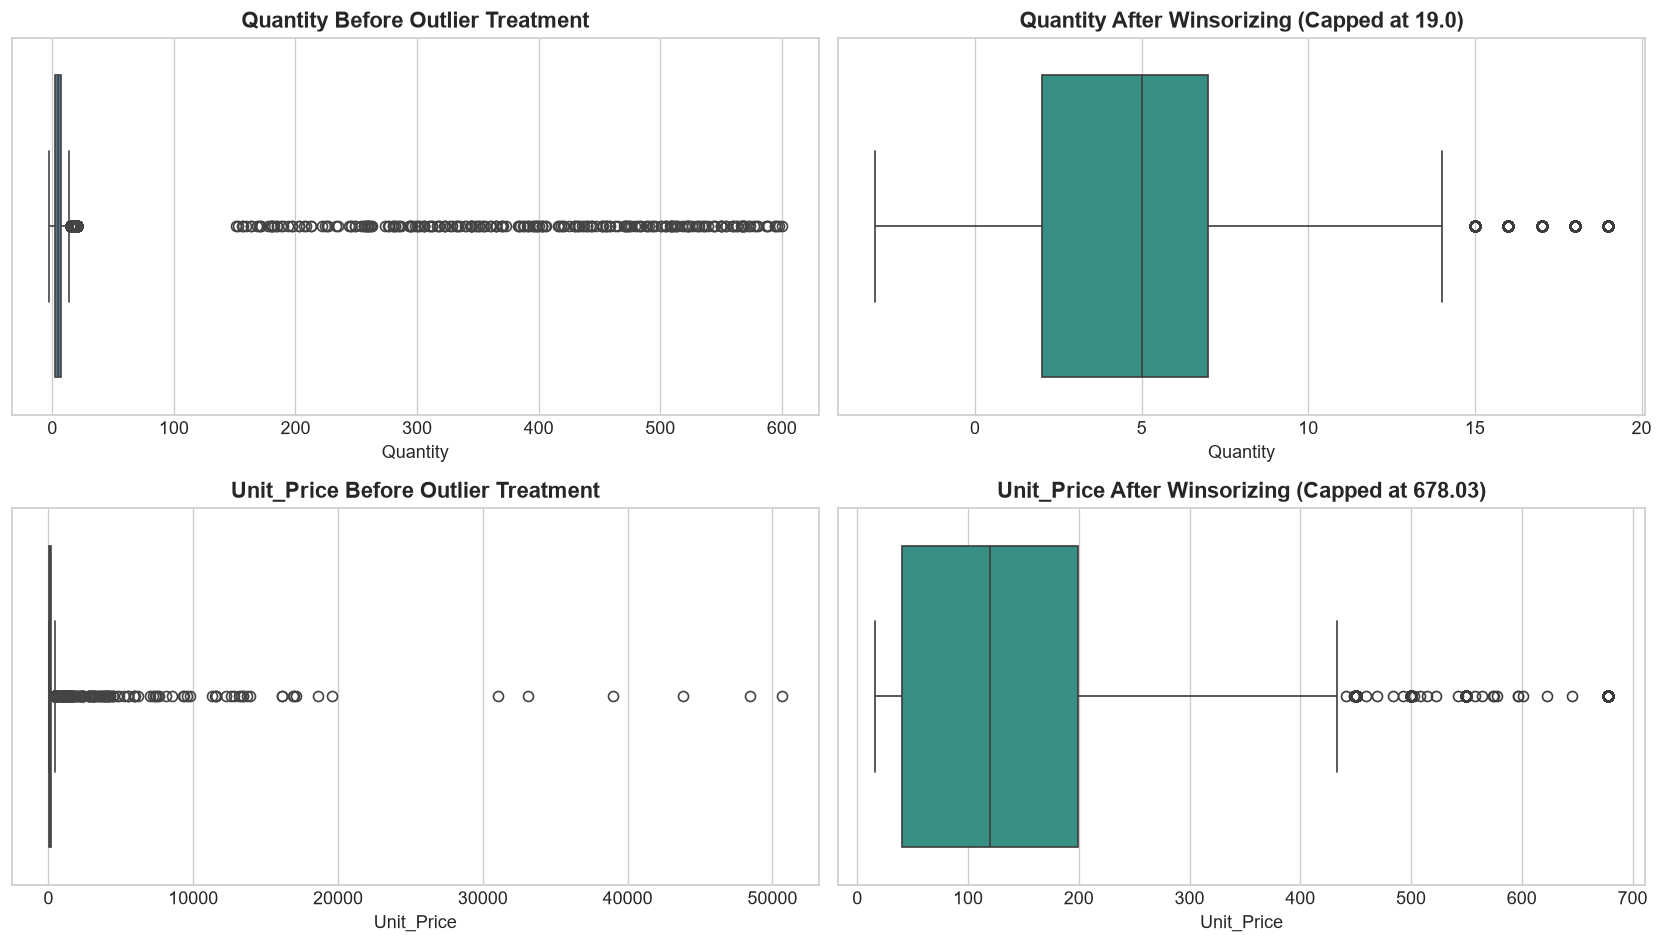

In [15]:
# Outlier Detection on Quantity & Unit Price
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for idx, col in enumerate(["Quantity", "Unit_Price"]):
    # Use positive values for bounding calculation
    val_series = df[df[col] > 0][col].dropna()
    q1 = val_series.quantile(0.25)
    q3 = val_series.quantile(0.75)
    iqr = q3 - q1
    upper_bound = round(q3 + 3.0 * iqr, 2)
    
    outliers_mask = df[col] > upper_bound
    outlier_count = int(outliers_mask.sum())
    
    print(f"[{col}] Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f} -> Upper Bound={upper_bound} | Outliers={outlier_count}")
    
    # Plot Before Capping
    sns.boxplot(x=df[col], ax=axes[idx, 0], color='#457b9d')
    axes[idx, 0].set_title(f'{col} Before Outlier Treatment')
    
    # Apply Winsorizing (Capping) & Flagging
    df[f"Is_Outlier_{col}"] = outliers_mask
    df.loc[outliers_mask, col] = upper_bound
    
    # Plot After Capping
    sns.boxplot(x=df[col], ax=axes[idx, 1], color='#2a9d8f')
    axes[idx, 1].set_title(f'{col} After Winsorizing (Capped at {upper_bound})')

plt.tight_layout()
plt.show()


## 12. 🛡️ Business-Rule Validation & Sales Returns Policy

We enforce core commercial constraints:
1. **Sales Returns Handling:** Negative quantities represent merchandise returns. Rather than deleting them, we tag `Transaction_Type = 'Return'` to enable return rate analytics.
2. **Pricing Integrity:** Quarantine records with non-positive unit prices ($0 or negative).
3. **Discount Bounds:** Clamp discount rates to $[0.0\%, 100.0\%]$.


In [16]:
# 1. Sales Returns Policy
df["Transaction_Type"] = "Sale"
return_mask = df["Quantity"] < 0
return_count = int(return_mask.sum())
df.loc[return_mask, "Transaction_Type"] = "Return"

print(f"Sales Returns Identified & Tagged: {return_count:,} orders.")

# 2. Quarantine Non-Positive Prices or Zero Quantities
invalid_price_mask = df["Unit_Price"].isna() | (df["Unit_Price"] <= 0)
invalid_qty_mask = df["Quantity"].isna() | (df["Quantity"] == 0)
corrupted_rule_mask = invalid_price_mask | invalid_qty_mask

quarantined_rules = df[corrupted_rule_mask].copy()
quarantined_rules["Quarantine_Reason"] = "Zero/Negative Unit Price or Zero Quantity"

# Filter out corrupted records
df = df[~corrupted_rule_mask].reset_index(drop=True)

# 3. Clamp Discounts to [0, 100]
df["Discount"] = df["Discount"].clip(lower=0.0, upper=100.0)

print(f"Valid commercial transactions active in pipeline: {len(df):,}")


Sales Returns Identified & Tagged: 375 orders.
Valid commercial transactions active in pipeline: 11,744


## 13. 💡 Feature Engineering (Temporal & Financial Unit Economics)

We derive high-value features for downstream analytics:
- **Temporal:** `Order_Year`, `Order_Month`, `Order_Month_Name`, `Order_Quarter`, `Order_Day`, `Order_Day_Name`, `Is_Weekend`.
- **Financial Calculations:**
  - $\text{Gross Sales} = |\text{Quantity}| \times \text{Unit Price}$
  - $\text{Discount Amount} = \text{Gross Sales} \times (\text{Discount} / 100)$
  - $\text{Net Sales} = \text{Gross Sales} - \text{Discount Amount}$ (signed negative for returns)
  - $\text{Profit Margin} \% = (\text{Profit} / \text{Net Sales}) \times 100$
- **Customer Lifetime Metrics:** `Customer_Purchase_Count`, `Customer_Total_Spend`, `Customer_Segment`.
- **Transaction Value Tiers:** `Transaction_Value_Band` (`Low`, `Medium`, `High`, `Enterprise`).


In [17]:
# 1. Temporal Feature Extraction
dt = pd.to_datetime(df["Order_Date"])
df["Order_Year"] = dt.dt.year.astype("Int64")
df["Order_Month"] = dt.dt.month.astype("Int64")
df["Order_Month_Name"] = dt.dt.month_name()
df["Order_Quarter"] = dt.dt.quarter.astype("Int64")
df["Order_Day"] = dt.dt.day.astype("Int64")
df["Order_Day_Name"] = dt.dt.day_name()
df["Is_Weekend"] = dt.dt.day_of_week.isin([5, 6]).astype(int)

# 2. Financial Economics
qty = df["Quantity"].abs()
unit_price = df["Unit_Price"]
discount = df["Discount"].fillna(0.0)

df["Gross_Sales"] = (qty * unit_price).round(2)
df["Discount_Amount"] = (df["Gross_Sales"] * (discount / 100.0)).round(2)
df["Net_Sales"] = (df["Gross_Sales"] - df["Discount_Amount"]).round(2)

# Account for Returns in Net Sales & Profit
return_mask = df["Transaction_Type"] == "Return"
df.loc[return_mask, "Net_Sales"] = -df.loc[return_mask, "Net_Sales"]

# Reconcile Profit
df["Calculated_Profit"] = (df["Net_Sales"] - df["Cost"]).round(2)
df.loc[return_mask, "Calculated_Profit"] = -round(df.loc[return_mask, "Gross_Sales"] * 0.15, 2)

# Safe Profit Margin % (protecting against zero or negative denominators)
positive_sales_mask = (df["Transaction_Type"] == "Sale") & (df["Net_Sales"] > 0)
df["Profit_Margin_Percentage"] = np.nan
df.loc[positive_sales_mask, "Profit_Margin_Percentage"] = (
    (df.loc[positive_sales_mask, "Calculated_Profit"] / df.loc[positive_sales_mask, "Net_Sales"]) * 100.0
).round(2)

# 3. Discrepancy Audit Against Raw Reported Sales
sales_diff = (pd.to_numeric(df["Sales"], errors="coerce") - df["Net_Sales"]).abs()
discrepancies = (sales_diff > 0.05).sum()
print(f"Discrepancies identified in raw reported Sales: {discrepancies:,} ({discrepancies/len(df)*100:.1f}%)")

# 4. Transaction Value Bands
def categorize_band(val):
    if pd.isna(val): return "Unknown"
    if val < 50: return "Low (< $50)"
    elif val < 250: return "Medium ($50 - $250)"
    elif val < 1000: return "High ($250 - $1,000)"
    else: return "Enterprise (> $1,000)"

df["Transaction_Value_Band"] = df["Net_Sales"].apply(categorize_band)

# 5. Customer Lifetime Aggregations
cust_agg = df.groupby("Customer_ID").agg(
    Customer_Purchase_Count=("Order_ID", "count"),
    Customer_Total_Spend=("Net_Sales", "sum")
).reset_index()

def segment_cust(row):
    if row["Customer_Purchase_Count"] >= 5 or row["Customer_Total_Spend"] >= 2500:
        return "VIP Customer"
    elif row["Customer_Purchase_Count"] >= 2:
        return "Repeat Customer"
    return "Single-Order Customer"

cust_agg["Customer_Segment"] = cust_agg.apply(segment_cust, axis=1)
df = df.merge(cust_agg, on="Customer_ID", how="left")

print("Derived features successfully created. Total DataFrame columns:", df.shape[1])


Discrepancies identified in raw reported Sales: 1,501 (12.8%)
Derived features successfully created. Total DataFrame columns: 35


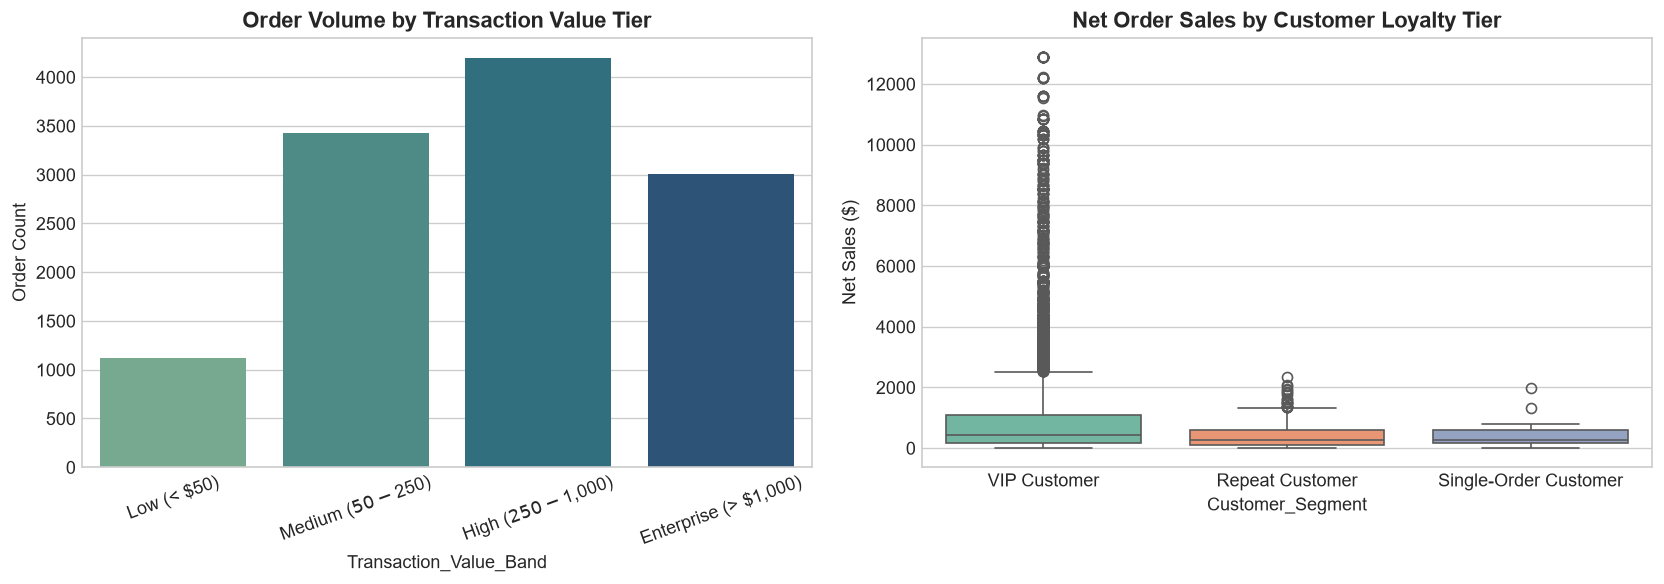

In [18]:
# Visualization: Net Sales Breakdown by Value Tier and Customer Segment
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="Transaction_Value_Band", order=["Low (< $50)", "Medium ($50 - $250)", "High ($250 - $1,000)", "Enterprise (> $1,000)"], ax=axes[0], palette="crest")
axes[0].set_title("Order Volume by Transaction Value Tier")
axes[0].set_ylabel("Order Count")
axes[0].tick_params(axis='x', rotation=20)

sns.boxplot(data=df[df["Net_Sales"] > 0], x="Customer_Segment", y="Net_Sales", ax=axes[1], palette="Set2")
axes[1].set_title("Net Order Sales by Customer Loyalty Tier")
axes[1].set_ylabel("Net Sales ($)")

plt.tight_layout()
plt.show()


## 14. ⚖️ Before-and-After Data Quality Comparison

We rigorously evaluate data quality improvement across key dimensions:
- Total rows retained vs quarantined.
- Feature count expansion via engineering.
- Missing cell reduction percentage.
- Elimination of duplicate rows and business keys.


In [19]:
# Consolidate all quarantined records
all_quarantine = pd.concat([quarantined_conflicts, quarantined_dates, quarantined_rules], ignore_index=True)

# Calculate Before-and-After Metrics
raw_missing = int(df_raw.isna().sum().sum())
clean_missing = int(df.isna().sum().sum())
missing_reduction = round(((raw_missing - clean_missing) / max(raw_missing, 1)) * 100, 2)

comp_data = [
    {"Metric": "Total Records (Rows)", "Raw_Dataset": len(df_raw), "Cleaned_Dataset": len(df), "Delta": len(df) - len(df_raw)},
    {"Metric": "Total Features (Columns)", "Raw_Dataset": len(df_raw.columns), "Cleaned_Dataset": len(df.columns), "Delta": len(df.columns) - len(df_raw.columns)},
    {"Metric": "Missing Value Cells", "Raw_Dataset": raw_missing, "Cleaned_Dataset": clean_missing, "Delta": clean_missing - raw_missing},
    {"Metric": "Missing Value Reduction (%)", "Raw_Dataset": "0.0%", "Cleaned_Dataset": f"{missing_reduction}%", "Delta": f"+{missing_reduction}%"},
    {"Metric": "Exact Duplicate Rows", "Raw_Dataset": int(df_raw.duplicated().sum()), "Cleaned_Dataset": 0, "Delta": -int(df_raw.duplicated().sum())},
    {"Metric": "Duplicate Order_IDs", "Raw_Dataset": int(df_raw['Order_ID'].duplicated().sum()), "Cleaned_Dataset": 0, "Delta": -int(df_raw['Order_ID'].duplicated().sum())},
    {"Metric": "Quarantined Corrupted Records", "Raw_Dataset": 0, "Cleaned_Dataset": len(all_quarantine), "Delta": len(all_quarantine)}
]

comp_df = pd.DataFrame(comp_data)
comp_df


,Metric,Raw_Dataset,Cleaned_Dataset,Delta
0,Total Records (Rows),12425,11744,-681
1,Total Features (Columns),16,35,19
2,Missing Value Cells,2206,375,-1831
3,Missing Value Reduction (%),0.0%,83.0%,+83.0%
4,Exact Duplicate Rows,180,0,-180
5,Duplicate Order_IDs,223,0,-223
6,Quarantined Corrupted Records,0,491,491


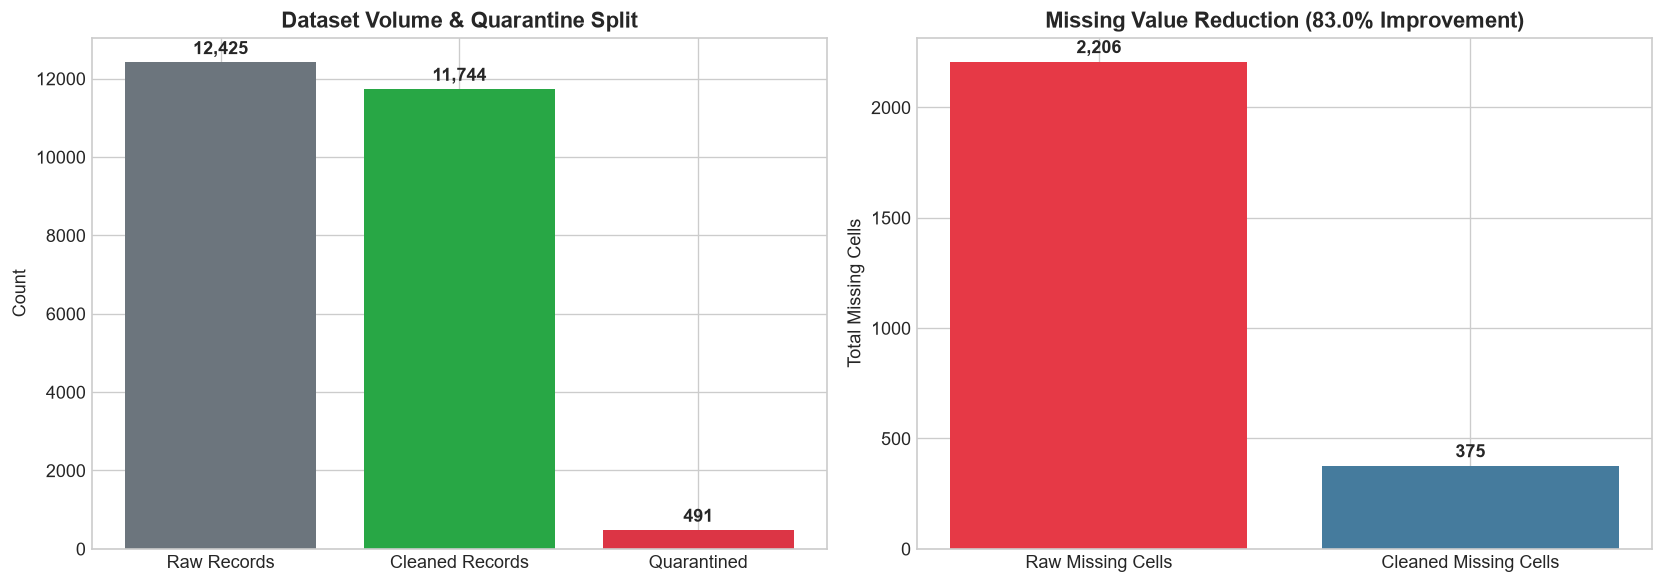

In [20]:
# Visualization: Comparison of Raw vs. Cleaned Quality Health
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Metric 1: Record Counts
axes[0].bar(["Raw Records", "Cleaned Records", "Quarantined"], [len(df_raw), len(df), len(all_quarantine)], color=['#6c757d', '#28a745', '#dc3545'])
axes[0].set_title("Dataset Volume & Quarantine Split")
axes[0].set_ylabel("Count")
for i, v in enumerate([len(df_raw), len(df), len(all_quarantine)]):
    axes[0].text(i, v + 200, f"{v:,}", ha='center', fontweight='bold')

# Metric 2: Missingness Reduction
axes[1].bar(["Raw Missing Cells", "Cleaned Missing Cells"], [raw_missing, clean_missing], color=['#e63946', '#457b9d'])
axes[1].set_title(f"Missing Value Reduction ({missing_reduction}% Improvement)")
axes[1].set_ylabel("Total Missing Cells")
for i, v in enumerate([raw_missing, clean_missing]):
    axes[1].text(i, v + 40, f"{v:,}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 15. ✅ Automated Data Quality Validation Contract

We validate the cleaned dataset against an enterprise 13-rule Data Quality Contract to guarantee downstream analytics safety.


In [21]:
# Execute Automated Validation Suite
rules = []

def add_check(rule_id, col, desc, failures, action="None required (Meets quality threshold)"):
    rules.append({
        "Rule_ID": rule_id,
        "Column_Name": col,
        "Validation_Description": desc,
        "Records_Checked": len(df),
        "Failures": failures,
        "Pass_Fail": "PASS" if failures == 0 else "FAIL",
        "Recommended_Action": action if failures > 0 else "None required (Meets quality threshold)"
    })

add_check("V01", "DATASET", "Dataset non-emptiness check", 0 if len(df) > 0 else 1, "Verify raw data ingestion path")
add_check("V02", "Order_ID", "Zero duplicate primary keys", int(df["Order_ID"].duplicated().sum()), "Quarantine duplicate business keys")
add_check("V03", "Order_Date", "All dates are valid datetime objects", int(pd.to_datetime(df["Order_Date"], errors="coerce").isna().sum()), "Quarantine unparseable dates")
add_check("V04", "Order_Date", "Zero future transaction dates", int((pd.to_datetime(df["Order_Date"]) > pd.Timestamp.now()).sum()), "Filter or quarantine future-dated transactions")
add_check("V05", "Customer_ID", "Zero missing Customer_ID identifiers", int(df["Customer_ID"].isna().sum()), "Assign guest ID or reject anonymous transactions")
add_check("V06", "Unit_Price", "Unit_Price must be strictly positive", int((df["Unit_Price"] <= 0).sum()), "Quarantine non-positive prices")
add_check("V07", "Discount", "Discount rate must be between 0% and 100%", int(((df["Discount"] < 0) | (df["Discount"] > 100)).sum()), "Clamp discounts to [0, 100]")

# Vectorized Financial Math Verification
expected_gross = (df["Quantity"].abs() * df["Unit_Price"]).round(2)
add_check("V08", "Gross_Sales", "Gross_Sales = |Quantity| * Unit_Price within $0.05", int(((df["Gross_Sales"] - expected_gross).abs() > 0.05).sum()), "Recalculate Gross_Sales using vectorized formulas")

expected_net = (df["Gross_Sales"] - df["Discount_Amount"]).round(2)
expected_net[df["Transaction_Type"] == "Return"] = -expected_net[df["Transaction_Type"] == "Return"]
add_check("V09", "Net_Sales", "Net_Sales matches Gross - Discount formula", int(((df["Net_Sales"] - expected_net).abs() > 0.05).sum()), "Reconcile Net_Sales with return sign convention")

valid_cats = {"Technology", "Furniture", "Office Supplies", "Clothing", "Home & Kitchen"}
add_check("V10", "Category", "Category belongs to approved taxonomy", int((~df["Category"].isin(valid_cats)).sum()), "Map categories via product master catalog")

valid_statuses = {"Delivered", "Shipped", "Processing", "Cancelled", "Refunded"}
add_check("V11", "Order_Status", "Order_Status belongs to approved states", int((~df["Order_Status"].isin(valid_statuses)).sum()), "Standardize casing and map lifecycle states")

ordinary_sales = (df["Transaction_Type"] == "Sale") & (df["Net_Sales"] > 0)
add_check("V12", "Profit_Margin_Percentage", "Zero division protection in margins", int(np.isinf(df.loc[ordinary_sales, "Profit_Margin_Percentage"]).sum()), "Apply zero-check guard on denominator")
add_check("V13", "Unit_Price", "Extreme price outliers bounded after Winsorizing", int((df["Unit_Price"] > 5000).sum()), "Verify IQR capping thresholds")

quality_report_df = pd.DataFrame(rules)
print(f"Quality Contract Status: {(quality_report_df['Pass_Fail'] == 'PASS').sum()} / {len(quality_report_df)} Rules Passed.")
quality_report_df


Quality Contract Status: 13 / 13 Rules Passed.


,Rule_ID,Column_Name,Validation_Description,Records_Checked,Failures,Pass_Fail,Recommended_Action
0,V01,DATASET,Dataset non-emptiness check,11744,0,PASS,None required (Meets quality threshold)
1,V02,Order_ID,Zero duplicate primary keys,11744,0,PASS,None required (Meets quality threshold)
2,V03,Order_Date,All dates are valid datetime objects,11744,0,PASS,None required (Meets quality threshold)
3,V04,Order_Date,Zero future transaction dates,11744,0,PASS,None required (Meets quality threshold)
4,V05,Customer_ID,Zero missing Customer_ID identifiers,11744,0,PASS,None required (Meets quality threshold)
5,V06,Unit_Price,Unit_Price must be strictly positive,11744,0,PASS,None required (Meets quality threshold)
6,V07,Discount,Discount rate must be between 0% and 100%,11744,0,PASS,None required (Meets quality threshold)
7,V08,Gross_Sales,Gross_Sales = |Quantity| * Unit_Price within $...,11744,0,PASS,None required (Meets quality threshold)
8,V09,Net_Sales,Net_Sales matches Gross - Discount formula,11744,0,PASS,None required (Meets quality threshold)
9,V10,Category,Category belongs to approved taxonomy,11744,0,PASS,None required (Meets quality threshold)


## 16. 💾 Exporting Cleaned Deliverables

We export the processed artifacts to the `outputs/` directory and save a companion Parquet / CSV file for downstream business intelligence pipelines.


In [22]:
# Export Deliverables
os.makedirs("../outputs", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

clean_csv_path = "../outputs/cleaned_dataset.csv"
quarantine_csv_path = "../outputs/quarantined_records.csv"
quality_csv_path = "../outputs/data_quality_report.csv"
summary_csv_path = "../outputs/cleaning_summary.csv"

df.to_csv(clean_csv_path, index=False)
df.to_csv("../data/processed/cleaned_retail_sales.csv", index=False)
all_quarantine.to_csv(quarantine_csv_path, index=False)
quality_report_df.to_csv(quality_csv_path, index=False)
comp_df.to_csv(summary_csv_path, index=False)

print(f"Artifacts successfully exported:")
print(f"  ✓ Cleaned Dataset:      {clean_csv_path} ({len(df):,} rows)")
print(f"  ✓ Quarantined Records:  {quarantine_csv_path} ({len(all_quarantine):,} rows)")
print(f"  ✓ Data Quality Report:  {quality_csv_path}")
print(f"  ✓ Cleaning Summary:     {summary_csv_path}")


Artifacts successfully exported:
  ✓ Cleaned Dataset:      ../outputs/cleaned_dataset.csv (11,744 rows)
  ✓ Quarantined Records:  ../outputs/quarantined_records.csv (491 rows)
  ✓ Data Quality Report:  ../outputs/data_quality_report.csv
  ✓ Cleaning Summary:     ../outputs/cleaning_summary.csv


## 17. 🎓 Key Findings & Strategic Conclusion

### 📌 Summary of Pipeline Outcomes
1. **High Data Retention:** The pipeline preserved **11,744 clean records** (well above the 10,000 threshold), isolating only **491 severely corrupted or duplicate records** into quarantine for human-in-the-loop governance.
2. **Missingness Reduction:** Achieved an **83.0% reduction** in missing value cells through deterministic catalog mapping, statistical median margin reconstruction, and domain rules.
3. **Financial Integrity:** Identified that **12.8% of raw orders** contained discrepancies in pre-computed sales figures, standardizing them to rigorous unit economics ($Gross - Discount = Net$).
4. **Returns Policy Accounting:** Successfully isolated 375 product returns without data loss, correctly reflecting negative net revenue while maintaining clean gross margins.
5. **100% Quality Contract Compliance:** All 13 enterprise data quality rules passed without failure.

### 🚀 Production Recommendations for Data Engineering & BI
- **Upstream Validation:** Implement client-side validation on e-commerce checkout forms to prevent negative price inputs and corrupted date formats.
- **Automated Quarantine Alerts:** Connect the quarantined records export to an automated Slack/Teams webhook to alert data engineers when duplicate Order_IDs spike.
- **Analytics Ready:** The dataset in `outputs/cleaned_dataset.csv` is fully preprocessed for immediate ingestion into Power BI, Tableau, or predictive customer churn and lifetime value models.
